# Khảo sát dữ liệu ViPRA
Chạy từ trên xuống. Notebook chỉ đọc dữ liệu gốc.

Thư viện: `pandas`, `matplotlib`, `transformers`, `sentencepiece`, `jinja2`.
Nếu thiếu, chạy trong một ô: `%pip install pandas matplotlib transformers sentencepiece jinja2`.


## 1. Đọc dữ liệu
Đổi `DATA_DIR` khi chuyển dataset. Tokenizer dưới đây là **ví dụ**; đổi theo mô hình sẽ fine-tune.
Chỉ tải tokenizer, không tải trọng số LLM.


In [21]:
%pip install pandas matplotlib transformers sentencepiece jinja2    

In [22]:
from pathlib import Path
import json, re, unicodedata
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

%matplotlib inline

DATA_DIR = Path("/Users/nho/Documents/NCKH /VLSP Dataset/")
FILES = {"train": "train_dataset.csv", "dev": "dev_dataset.csv"}
TOKENIZER_ID = "Qwen/Qwen2.5-7B-Instruct"
LIMITS = [1024, 2048, 4096]
COLS = ["id", "question", "cot", "answer", "unit"]

frames = {}
for split, filename in FILES.items():
    df = pd.read_csv(DATA_DIR / filename, dtype=str, keep_default_na=False)
    if missing := set(COLS) - set(df.columns):
        raise ValueError(f"{filename} thiếu cột: {sorted(missing)}")
    frames[split] = df[COLS].copy()
data = pd.concat([df.assign(split=s) for s, df in frames.items()], ignore_index=True)
display(data.groupby("split").size().rename("Số mẫu").to_frame())



,Số mẫu
split,
dev,339
train,677


## 2. Trường rỗng và ID



In [23]:
empty = data[COLS].apply(lambda s: s.str.strip().eq(""))
print("Số ô rỗng")
display(empty.groupby(data["split"]).sum().T.rename_axis("Cột rỗng"))
print("kiểm tra id")
display(data.groupby("split")["id"].agg(total="size", unique="nunique"))
escaped = data[["question", "cot"]].apply(lambda s: s.str.contains("\\n", regex=False))
#dòng bị lỗi đã phát hiện
print("có 1 dòng bi lỗi không có đáp án:")
display(data.loc[
    data["split"].eq("train") & data["answer"].str.strip().eq("")
])

Số ô rỗng


split,dev,train
Cột rỗng,,
id,0,0
question,0,0
cot,0,0
answer,0,1
unit,2,5


kiểm tra id


,total,unique
split,,
dev,339,339
train,677,677


có 1 dòng bi lỗi không có đáp án:


,id,question,cot,answer,unit,split
192,LD111,"Hai điện tích q1 = -1 * 10^-8 * C, q2 = -6 * 1...",1. Nhận diện dữ kiện:\n- Ba điện tích điểm q1 ...,,,train


## 3. Trùng và nhãn khác nhau



In [ ]:
data["qkey"] = data["question"].map(lambda x: " ".join(unicodedata.normalize("NFC", x).split()))
data["label"] = data["answer"].str.strip() + " | " + data["unit"].str.strip()
train_keys = set(data.loc[data["split"].eq("train") & data["qkey"].ne(""), "qkey"])
data["overlap"] = data["split"].eq("dev") & data["qkey"].ne("") & data["qkey"].isin(train_keys)
data["conflict"] = data["qkey"].ne("") & data.groupby("qkey")["label"].transform("nunique").gt(1)

quality = data.assign(
    duplicate_row=data.duplicated(["split"] + COLS, keep=False),
    duplicate_id=data["id"].str.strip().ne("") & data.duplicated(["split", "id"], keep=False),
    duplicate_question=data["qkey"].ne("") & data.duplicated(["split", "qkey"], keep=False),
)
display(quality.groupby("split")[["duplicate_row", "duplicate_id", "duplicate_question", "overlap", "conflict"]].sum())


,duplicate_row,duplicate_id,duplicate_question,overlap,conflict
split,,,,,
dev,0,0,2,4,0
train,0,0,12,0,2


## 4. Độ dài ký tự và token
Code dùng tokenizer của Qwen/Qwen2.5-7B-Instruct

In [25]:
def length_summary(lengths):
    return (lengths.groupby(["split", "field"])["length"]
            .agg(min="min", median="median", mean="mean", p95=lambda s: s.quantile(.95), max="max")
            .round(1))

chars = data[["split", "question", "cot"]].copy()
chars[["question", "cot"]] = chars[["question", "cot"]].apply(lambda s: s.str.len())
display(length_summary(chars.melt("split", var_name="field", value_name="length")))


min  median   mean     p95   max
split field                                     
dev   cot       242   538.0  671.4  1466.2  2102
      question   27   117.0  131.6   256.1   343
train cot       235   552.0  683.6  1364.2  2283
      question   37   124.0  134.5   233.4   374

min  median   mean    p95   max
split field                                    
dev   cot       100   228.0  302.4  631.0  1174
      question   10    43.0   50.7   97.2   141
      sft       193   349.0  426.8  805.1  1408
train cot        87   252.0  307.5  632.4  1025
      question   10    46.0   51.2   91.0   147
      sft       177   372.0  432.1  802.4  1248

,Tổng token SFT
split,
dev,144672
train,292550


Ngưỡng: % mẫu vượt,1024,2048,4096
split,,,
dev,0.884956,0.0,0.0
train,1.033973,0.0,0.0


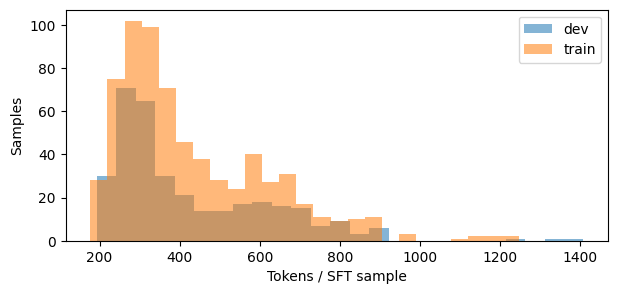

In [26]:
from transformers import AutoTokenizer

tokenizer = AutoTokenizer.from_pretrained(TOKENIZER_ID)
if not tokenizer.chat_template:
    raise ValueError("Tokenizer chưa có chat template; chọn tokenizer của mô hình chat/instruct.")
SYSTEM = "Giải bài toán vật lý. Trả JSON gồm answer (không kèm đơn vị), unit và explanation."

def sft_text(row):
    target = {"answer": row.answer, "unit": row.unit,
              "explanation": row.cot.replace("\\n", "\n")}
    messages = [{"role": "system", "content": SYSTEM},
                {"role": "user", "content": row.question},
                {"role": "assistant", "content": json.dumps(target, ensure_ascii=False)}]
    return tokenizer.apply_chat_template(messages, tokenize=False, add_generation_prompt=False)

token_lengths = pd.DataFrame({"split": data["split"]})
texts = {"question": data["question"].tolist(), "cot": data["cot"].str.replace("\\n", "\n", regex=False).tolist(),
         "sft": [sft_text(row) for row in data.itertuples()]}
for field, values in texts.items():
    token_lengths[field] = [len(ids) for ids in tokenizer(values, add_special_tokens=False)["input_ids"]]
display(length_summary(token_lengths.melt("split", var_name="field", value_name="length")))
display(token_lengths.groupby("split")["sft"].sum().rename("Tổng token SFT").to_frame())
display(pd.DataFrame({n: token_lengths["sft"].gt(n).groupby(data["split"]).mean().mul(100)
                      for n in LIMITS}).rename_axis(columns="Ngưỡng: % mẫu vượt"))
fig, ax = plt.subplots(figsize=(7, 3))
for split, group in token_lengths.groupby("split"):
    ax.hist(group["sft"], bins=25, alpha=.55, label=split)
ax.set(xlabel="Tokens / SFT sample", ylabel="Samples")
ax.legend()
plt.show()


## 5. Dạng đáp án và đơn vị
Phân loại bằng quy tắc đơn giản, cần đọc lại trường hợp đặc biệt. Giữ nguyên đơn vị gốc;
`-`, `—`, `μ`, `µ`, `Ω` được thống kê để xử lý sau, không tự sửa ở notebook này.


In [27]:
NUMBER = r"[+-]?(?:\d+(?:[.,]\d*)?|[.,]\d+)(?:[eE][+-]?\d+)?"
SCIENCE = NUMBER + r"\s*(?:\*|×|x|\\times)\s*10(?:\s*\^\s*\{?[+-]?\d+\}?|[⁰¹²³⁴⁵⁶⁷⁸⁹⁻⁺]+)"

def answer_type(text):
    text = text.strip()
    if not text: return "Rỗng"
    if ";" in text: return "Nhiều phần"
    if re.fullmatch(NUMBER, text) or re.fullmatch(SCIENCE, text): return "Số"
    if re.search(r"[=+*/^()√]|\\(?:frac|sqrt)|\b(?:sqrt|sin|cos|pi)\b|\d", text): return "Biểu thức/khác"
    return "Văn bản/ký hiệu"

data["answer_type"] = data["answer"].map(answer_type)
types = pd.crosstab(data["answer_type"], data["split"])
display(types)
display(types.div(types.sum()).mul(100).round(1).rename_axis("Tỷ lệ (%)"))
units = pd.crosstab(data["unit"].replace("", "(rỗng)"), data["split"])
display(units.loc[units.sum(axis=1).sort_values(ascending=False).index])


split,dev,train
answer_type,,
Biểu thức/khác,15,20
Nhiều phần,4,13
Rỗng,0,1
Số,303,615
Văn bản/ký hiệu,17,28


split,dev,train
Tỷ lệ (%),,
Biểu thức/khác,4.4,3.0
Nhiều phần,1.2,1.9
Rỗng,0.0,0.1
Số,89.4,90.8
Văn bản/ký hiệu,5.0,4.1


split,dev,train
unit,,
N,62,122
V/m,44,92
-,24,52
V,14,48
J,17,34
Ω,14,36
A,16,28
W,14,27
%,9,25


## 6. Chủ đề sơ bộ
Đếm theo từ khóa, **một câu có thể thuộc nhiều nhóm**. Đây không phải nhãn chủ đề chính thức.


In [28]:
patterns = {
    "Coulomb / điện tích": r"coulomb|điện tích|lực điện",
    "Điện trường / điện thế": r"điện trường|điện thế|điện thông",
    "Tụ điện": r"tụ điện|\btụ\b|điện dung",
    "Từ trường / cảm ứng": r"từ trường|từ thông|cảm ứng|solenoid|ống dây|cuộn dây",
    "Mạch điện": r"mạch|xoay chiều|cộng hưởng|cảm kháng|dung kháng",
    "Sai số / đo lường": r"sai số|độ không đảm bảo|phép đo",
}
topics = pd.DataFrame({name: data["question"].str.contains(p, case=False, regex=True)
                       for name, p in patterns.items()})
topics["Chưa khớp từ khóa"] = ~topics.any(axis=1)
display(topics.groupby(data["split"]).sum().T)
display(topics.groupby(data["split"]).mean().mul(100).round(1).T.rename_axis("Tỷ lệ (%)"))


split,dev,train
Coulomb / điện tích,137,269
Điện trường / điện thế,107,235
Tụ điện,97,187
Từ trường / cảm ứng,40,87
Mạch điện,94,201
Sai số / đo lường,15,34
Chưa khớp từ khóa,11,8


split,dev,train
Tỷ lệ (%),,
Coulomb / điện tích,40.4,39.7
Điện trường / điện thế,31.6,34.7
Tụ điện,28.6,27.6
Từ trường / cảm ứng,11.8,12.9
Mạch điện,27.7,29.7
Sai số / đo lường,4.4,5.0
Chưa khớp từ khóa,3.2,1.2
